# 2023 — Vision-Language Models (LLaVA-style)

**Papers:** Alayrac et al., *Flamingo* (2022); Li et al., *BLIP-2* (2023); Haotian Liu et al., *"Visual Instruction Tuning"* (**LLaVA**, 2023). Today's multimodal models (GPT-4o/5, Gemini, Claude, Qwen-VL, Llama 4) follow variants of the same recipe.

How do you give a language model eyes? LLaVA's recipe is simple:
1. take a **pre-trained vision encoder** (CLIP ViT) and a **pre-trained LLM**
2. add a small **projector** that maps image patch features into the LLM's token-embedding space, so each patch becomes a "visual token"
3. **stage 1:** freeze both models and train only the projector on image–caption pairs (feature alignment)
4. **stage 2:** unfreeze the LLM and train on image + instruction → answer data (visual instruction tuning)

Our toy version: images with **two handwritten digits side by side**. A small word-level language model learns to answer questions such as *"what is the left digit?"*, *"what is the sum?"* and *"is the left digit bigger?"*

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors()]
def make_pairs(X, y, n):
    i, j = torch.randint(0, len(X), (2, n), device=device)
    return torch.cat([X[i], X[j]], dim=3), y[i], y[j]                                  # (n, 1, 8, 16) images

NUM = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten",
       "eleven", "twelve", "thirteen", "fourteen", "fifteen", "sixteen", "seventeen", "eighteen"]
QUESTIONS = {"left": "what is the left digit ?", "right": "what is the right digit ?",
             "sum": "what is the sum of the digits ?", "bigger": "is the left digit bigger ?"}
def answer(kind, a, b):
    return {"left": NUM[a], "right": NUM[b], "sum": NUM[a + b], "bigger": "yes" if a > b else "no"}[kind]

words = ["<pad>", "<img>", "<eos>", "question", ":", "answer"] + sorted({w for q in QUESTIONS.values() for w in q.split()}) + NUM + ["yes", "no"]
stoi = {w: i for i, w in enumerate(dict.fromkeys(words))}; itos = {i: w for w, i in stoi.items()}; VOC = len(stoi)
N_IMG = 8                                                                              # visual tokens per image
def encode_text(kind, a=None, b=None):
    txt = f"question : {QUESTIONS[kind]} answer :" + (f" {answer(kind, a, b)} <eos>" if a is not None else "")
    return [stoi[w] for w in txt.split()]
print("vocabulary:", VOC, "words | example:", f"question : {QUESTIONS['sum']} answer : {answer('sum', 3, 9)}")

vocabulary: 38 words | example: question : what is the sum of the digits ? answer : twelve


## Pre-trained parts
**Vision encoder:** a small CNN pre-trained to classify single digits, then frozen. (LLaVA uses CLIP; this plays the same role.) We keep its 2×4 grid of 64-d features as 8 "patch" features.

**Language model:** a small causal Transformer pre-trained on text only, with answers *random*. So it knows the language but nothing about images. Like real multimodal LLMs, its sequences reserve 8 `<img>` placeholder slots in front of the text, where visual tokens will later go.

In [3]:
class VisionEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))        # 8x8 -> 2x2 grid, 8x16 -> 2x4
        self.cls = nn.Linear(64 * 4, 10)
    def patches(self, img): return self.net(img).flatten(2).transpose(1, 2)              # (B, n_patches, 64)
    def forward(self, img8): return self.cls(self.net(img8).flatten(1))

seed_everything(0)
venc = VisionEncoder().to(device); o = torch.optim.Adam(venc.parameters(), lr=2e-3)
for _ in range(800):
    idx = torch.randint(0, len(Xtr), (128,), device=device)
    l = F.cross_entropy(venc(Xtr[idx]), ytr[idx]); o.zero_grad(); l.backward(); o.step()
with torch.no_grad(): print(f"vision encoder pre-trained: single-digit accuracy {(venc(Xte).argmax(1) == yte).float().mean():.3f}")
venc.requires_grad_(False).eval()

class TinyLM(nn.Module):
    def __init__(self, d=128, n_layers=3, heads=4, max_len=32):
        super().__init__()
        self.emb, self.pos = nn.Embedding(VOC, d), nn.Embedding(max_len, d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.body = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False); self.head = nn.Linear(d, VOC)
    def forward(self, emb):                                                             # takes embeddings, so images can be prepended
        T = emb.shape[1]
        mask = torch.triu(torch.full((T, T), float("-inf"), device=emb.device), 1)
        return self.head(self.body(emb + self.pos(torch.arange(T, device=emb.device)), mask=mask, is_causal=True))

def batch_text(kinds, a, b):
    seqs = [encode_text(k, int(x), int(y)) for k, x, y in zip(kinds, a.tolist(), b.tolist())]
    T = max(map(len, seqs)); ids = torch.zeros(len(seqs), T, dtype=torch.long)
    for i, s in enumerate(seqs): ids[i, :len(s)] = torch.tensor(s)
    return ids.to(device)

def lm_loss(logits, ids, n_prefix):
    """Next-token loss on the text part only (padding ignored). With n_prefix visual tokens in front,
    the prediction for text token i sits at position n_prefix + i - 1."""
    pred = logits[:, n_prefix - 1:-1] if n_prefix else logits[:, :-1]
    tgt = ids if n_prefix else ids[:, 1:]
    return F.cross_entropy(pred.reshape(-1, VOC), tgt.reshape(-1), ignore_index=0)

seed_everything(0)
lm = TinyLM().to(device); o = torch.optim.Adam(lm.parameters(), lr=1e-3)
kinds_all = list(QUESTIONS)
img_slots = torch.full((128, N_IMG), stoi["<img>"], device=device)
for _ in range(600):                                                                    # text-only pre-training, random answers
    kinds = random.choices(kinds_all, k=128); a, b = torch.randint(0, 10, (2, 128))
    ids = batch_text(kinds, a, b)
    l = lm_loss(lm(lm.emb(torch.cat([img_slots, ids], 1))), ids, N_IMG); o.zero_grad(); l.backward(); o.step()
print(f"language model pre-trained on text only (final loss {l.item():.3f}); its answers carry no image information yet")

vision encoder pre-trained: single-digit accuracy 0.981


language model pre-trained on text only (final loss 0.279); its answers carry no image information yet


## Connect them: projector + visual tokens

In [4]:
projector = nn.Sequential(nn.Linear(64, 128), nn.GELU(), nn.Linear(128, 128)).to(device)   # LLaVA-1.5 uses a 2-layer MLP too

def vlm_logits(img, ids):
    vis = projector(venc.patches(img))                                                 # (B, 8, d) visual tokens
    return lm(torch.cat([vis, lm.emb(ids)], 1))

@torch.no_grad()
def evaluate(n=600):
    lm.eval(); img, a, b = make_pairs(Xte, yte, n); acc = {}
    for kind in kinds_all:
        ids = torch.tensor([encode_text(kind)] * n, device=device)
        pred = vlm_logits(img, ids)[:, -1].argmax(-1)
        target = torch.tensor([stoi[answer(kind, int(x), int(y))] for x, y in zip(a.tolist(), b.tolist())], device=device)
        acc[kind] = (pred == target).float().mean().item()
    lm.train(); return acc

def train_stage(params, steps, lr):
    o = torch.optim.Adam(params, lr=lr)
    for _ in range(steps):
        img, a, b = make_pairs(Xtr, ytr, 128); kinds = random.choices(kinds_all, k=128)
        ids = batch_text(kinds, a, b)
        l = lm_loss(vlm_logits(img, ids), ids, N_IMG); o.zero_grad(); l.backward(); o.step()

print("before any multimodal training:", {k: round(v, 2) for k, v in evaluate().items()})
lm.requires_grad_(False)
train_stage(projector.parameters(), 800, 2e-3)                                         # stage 1: projector only
print("after stage 1 (projector only):  ", {k: round(v, 2) for k, v in evaluate().items()})
lm.requires_grad_(True)
train_stage(list(projector.parameters()) + list(lm.parameters()), 1500, 5e-4)          # stage 2: projector + LM
print("after stage 2 (+ LM fine-tune):  ", {k: round(v, 2) for k, v in evaluate().items()})

before any multimodal training: {'left': 0.1, 'right': 0.1, 'sum': 0.08, 'bigger': 0.55}


after stage 1 (projector only):   {'left': 0.57, 'right': 0.5, 'sum': 0.22, 'bigger': 0.68}


after stage 2 (+ LM fine-tune):   {'left': 0.98, 'right': 0.96, 'sum': 0.9, 'bigger': 0.98}


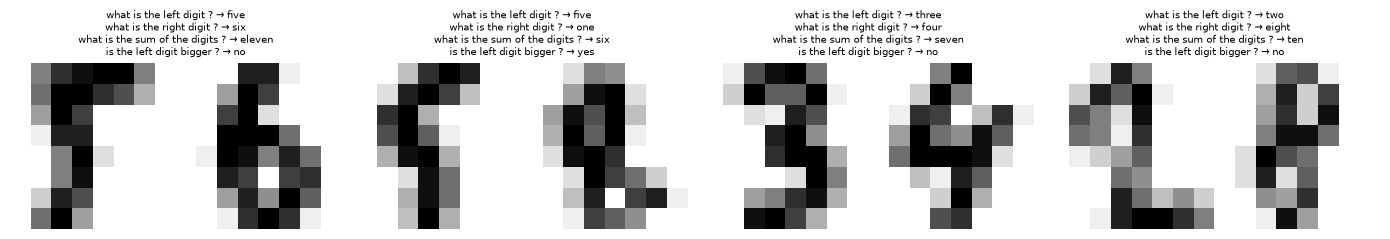

In [5]:
img, a, b = make_pairs(Xte, yte, 4)
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
with torch.no_grad():
    for j in range(4):
        lines = []
        for kind in kinds_all:
            ids = torch.tensor([encode_text(kind)], device=device)
            lines.append(f"{QUESTIONS[kind]} → {itos[vlm_logits(img[j:j + 1], ids)[0, -1].argmax().item()]}")
        axes[j].imshow(img[j, 0].cpu(), cmap="gray_r"); axes[j].axis("off"); axes[j].set_title("\n".join(lines), fontsize=7)
plt.tight_layout(); plt.show()

## Takeaways
- An LLM can "see" once image features are **projected into its embedding space** as extra tokens; nothing else in the architecture changes.
- Stage 1 (projector only) teaches the frozen LLM to *read* the visual tokens; stage 2 (fine-tuning the LLM too) is where it learns to *reason* over them. Compare how much each stage helps the single-digit questions vs. the sum and the comparison.
- Modern VLMs use the same idea at scale, with better encoders (SigLIP, native-resolution ViTs) and interleaved image–text pre-training.